Projet Machine Learning : Analyse et Modélisation d’un jeu de données 

Partie	1	:	Lecture	des	données

In [2]:
# 1. Importer les bibliothèques nécessaires
import pandas as pd
import numpy as np

# 2. Charger les données avec pandas
# Remplacez "chemin/vers/fichier.csv" par le chemin réel de votre fichier CSV
df = pd.read_csv("C:\\Users\\segui\\Desktop\\Machine Learning\\Projet_TI508A_2025\\patients_synthetic_1000.csv")

# 3. Afficher un aperçu des données
# Affiche les 5 premières lignes
print("Aperçu des 5 premières lignes du jeu de données :")
print(df.head())

# Informations générales sur le jeu de données : types de variables, valeurs manquantes, mémoire utilisée
print("\nInformations générales sur le jeu de données :")
print(df.info())

# Statistiques descriptives des variables numériques
print("\nStatistiques descriptives des variables numériques :")
print(df.describe())


Aperçu des 5 premières lignes du jeu de données :
   patient_id  age     sex smoker physical_activity diet_quality   bmi  \
0           1   55  Female    Yes            Medium         Poor  33.7   
1           2   32    Male    Yes            Medium         Poor  28.9   
2           3   63    Male     No               Low      Average  21.3   
3           4   66    Male     No               Low         Poor  31.3   
4           5   18    Male     No            Medium         Good  27.4   

   systolic_bp  diastolic_bp  glucose_fasting  hba1c  cholesterol_total  \
0          129            85            113.2   4.75                226   
1           99            62             98.2   4.69                177   
2          104            72             93.6   5.03                167   
3          131            87            114.2   5.37                220   
4           95            61             88.3   4.98                142   

   hdl_cholesterol  ldl_cholesterol  triglycerides dia

Explications :

pd.read_csv() permet de charger un fichier CSV dans un DataFrame pandas.

head() affiche un aperçu des premières lignes pour voir les valeurs réelles.

info() montre le nombre de lignes, de colonnes, les types de données et la présence de valeurs manquantes.

describe() fournit la moyenne, l’écart-type, le minimum, le maximum et les quartiles des variables numériques.

Partie	2	:	Analyse	des	données	
1. Description du Jeu de Données

In [3]:
# Nombre de lignes et de colonnes
n_lignes, n_colonnes = df.shape
print(f"Le jeu de données contient {n_lignes} lignes et {n_colonnes} colonnes.\n")

# Identification des types de variables
# Variables numériques (continues)
variables_numeriques = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("Variables continues :")
print(variables_numeriques, "\n")

# Variables catégorielles
variables_categorielles = df.select_dtypes(include=['object', 'category']).columns.tolist()
print("Variables catégorielles :")
print(variables_categorielles, "\n")

# Affichage d'un résumé par type de variable
print("Résumé des types de données :")
print(df.dtypes)


Le jeu de données contient 1000 lignes et 17 colonnes.

Variables continues :
['patient_id', 'age', 'bmi', 'systolic_bp', 'diastolic_bp', 'glucose_fasting', 'hba1c', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides'] 

Variables catégorielles :
['sex', 'smoker', 'physical_activity', 'diet_quality', 'diabetes', 'risk_category'] 

Résumé des types de données :
patient_id             int64
age                    int64
sex                   object
smoker                object
physical_activity     object
diet_quality          object
bmi                  float64
systolic_bp            int64
diastolic_bp           int64
glucose_fasting      float64
hba1c                float64
cholesterol_total      int64
hdl_cholesterol        int64
ldl_cholesterol        int64
triglycerides          int64
diabetes              object
risk_category         object
dtype: object


Explications :

df.shape donne le nombre de lignes et de colonnes du DataFrame.

select_dtypes(include=...) permet de filtrer les colonnes selon leur type de données.

df.dtypes fournit un résumé complet des types de chaque colonne.

2. Nettoyage et Exploration des Données 

Valeurs manquantes par colonne :
patient_id           0
age                  0
sex                  0
smoker               0
physical_activity    0
diet_quality         0
bmi                  0
systolic_bp          0
diastolic_bp         0
glucose_fasting      0
hba1c                0
cholesterol_total    0
hdl_cholesterol      0
ldl_cholesterol      0
triglycerides        0
diabetes             0
risk_category        0
dtype: int64


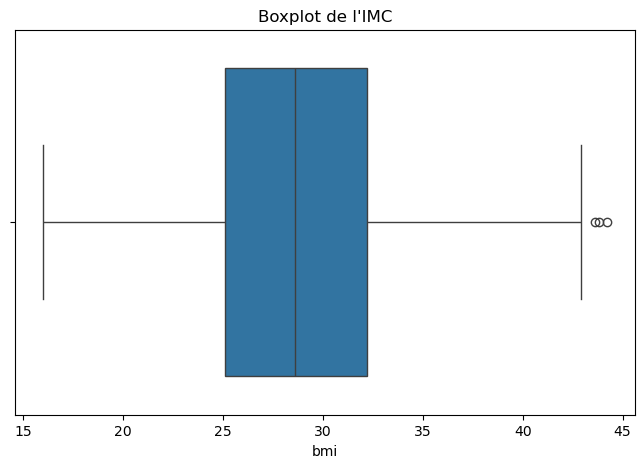

Statistiques descriptives des variables continues :
        patient_id         age          bmi  systolic_bp  diastolic_bp  \
count  1000.000000  1000.00000  1000.000000  1000.000000   1000.000000   
mean    500.500000    49.68300    28.614438   117.693000     73.691000   
std     288.819436    16.18408     5.210959    13.649581      8.209075   
min       1.000000    18.00000    16.000000    85.000000     50.000000   
25%     250.750000    38.00000    25.100000   108.000000     68.000000   
50%     500.500000    50.00000    28.600000   118.000000     73.000000   
75%     750.250000    60.00000    32.225000   127.000000     79.000000   
max    1000.000000    90.00000    42.912500   164.000000    101.000000   

       glucose_fasting        hba1c  cholesterol_total  hdl_cholesterol  \
count      1000.000000  1000.000000        1000.000000      1000.000000   
mean        101.677700     4.849330         193.668000        51.220000   
std          14.620435     0.304421          37.471481  

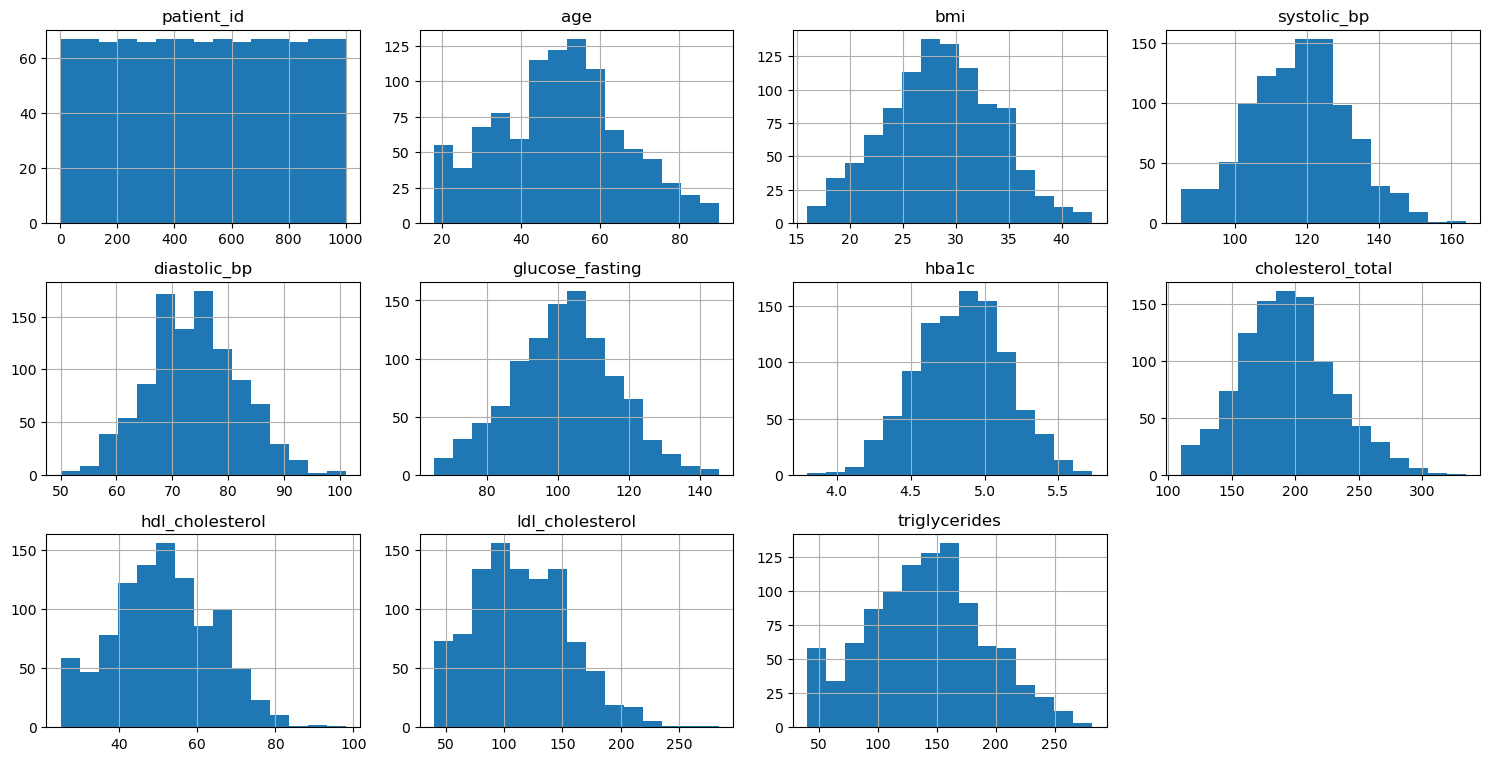

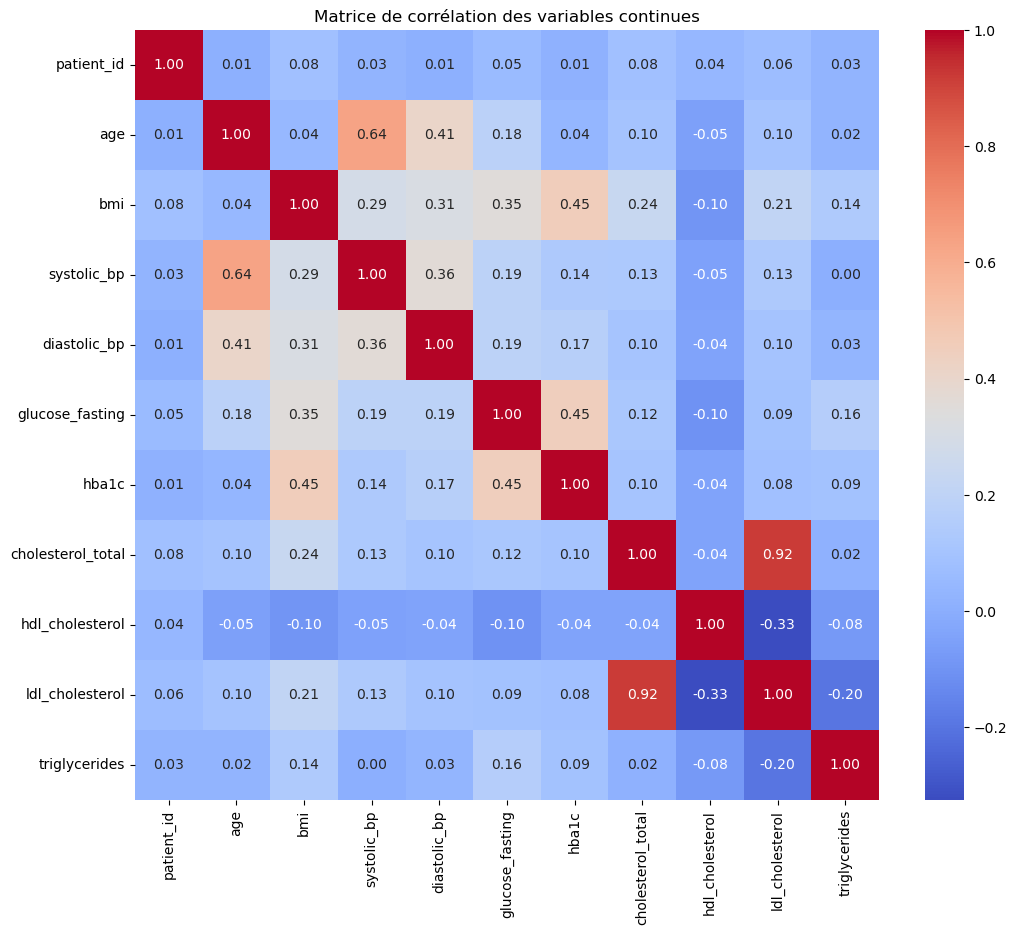

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Détection des données manquantes
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())

# Option pour traiter les données manquantes : suppression ou imputation
# Suppression des lignes avec valeurs manquantes
# df_clean = df.dropna()

# Imputation par la moyenne pour les colonnes numériques
df_clean = df.copy()
for col in df_clean.select_dtypes(include=['int64', 'float64']):
    df_clean[col] = df_clean[col].fillna(df_clean[col].mean())

# 2. Détection et traitement des valeurs aberrantes (exemple avec l'IMC)
# Boxplot pour visualiser les outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df_clean['bmi'])
plt.title("Boxplot de l'IMC")
plt.show()

# Option pour traiter les outliers : remplacer par les bornes
Q1 = df_clean['bmi'].quantile(0.25)
Q3 = df_clean['bmi'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR
df_clean['bmi'] = np.where(df_clean['bmi'] < lower_bound, lower_bound, df_clean['bmi'])
df_clean['bmi'] = np.where(df_clean['bmi'] > upper_bound, upper_bound, df_clean['bmi'])

# 3. Analyse descriptive des variables continues
desc_stats = df_clean.describe()
print("Statistiques descriptives des variables continues :")
print(desc_stats)

# Histogrammes des variables continues
numerical_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns
df_clean[numerical_cols].hist(bins=15, figsize=(15,10), layout=(4,4))
plt.tight_layout()
plt.show()

# 4. Visualisation des corrélations
plt.figure(figsize=(12,10))
corr_matrix = df_clean[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matrice de corrélation des variables continues")
plt.show()


Explications :

isnull().sum() permet de détecter les valeurs manquantes par colonne.

Pour les outliers, on utilise le boxplot et la règle de l'IQR (interquartile range).

describe() fournit la moyenne, médiane approximative, écart-type, min/max, etc.

hist() permet de visualiser la distribution des variables continues.

sns.heatmap() affiche la matrice de corrélation pour identifier les relations linéaires.

3. Clustering 
Cette	étape	consiste	à	appliquer	deux	méthodes	de	clustering	:	Kmeans	et	la	Classification	
Ascendante	Hiérarchique	(CAH).

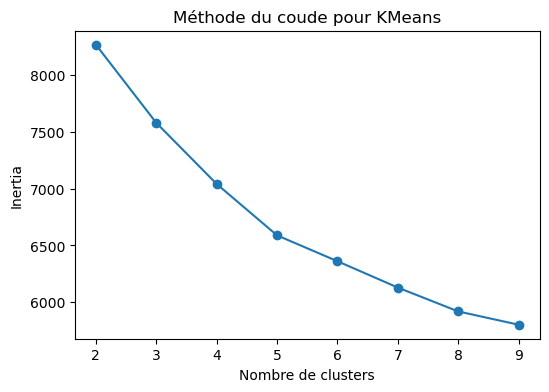

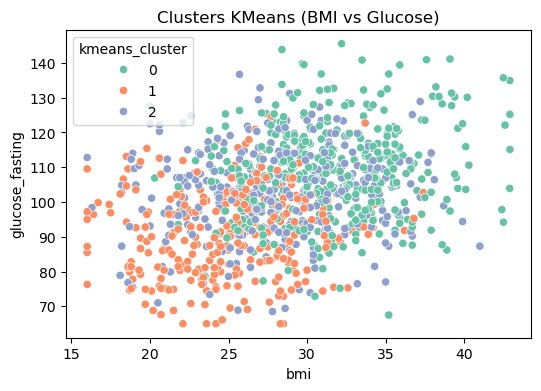

In [11]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.cluster._kmeans")

# Import des bibliothèques nécessaires
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# Sélection des variables continues
continuous_cols = ['age', 'bmi', 'systolic_bp', 'diastolic_bp', 
                   'glucose_fasting', 'hba1c', 'cholesterol_total', 
                   'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides']
X = df_clean[continuous_cols]

# Normalisation des variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Détermination du nombre optimal de clusters (ex: méthode du coude)
inertia = []
K_range = range(2, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Visualisation de la méthode du coude
plt.figure(figsize=(6,4))
plt.plot(K_range, inertia, marker='o')
plt.xlabel("Nombre de clusters")
plt.ylabel("Inertia")
plt.title("Méthode du coude pour KMeans")
plt.show()

# Application de KMeans avec un nombre choisi de clusters, par exemple K=3
k_opt = 3
kmeans = KMeans(n_clusters=k_opt, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Ajout des labels KMeans au DataFrame
df_clean['kmeans_cluster'] = kmeans_labels

# Visualisation des clusters (exemple BMI vs Glucose)
plt.figure(figsize=(6,4))
sns.scatterplot(x='bmi', y='glucose_fasting', hue='kmeans_cluster', data=df_clean, palette='Set2')
plt.title("Clusters KMeans (BMI vs Glucose)")
plt.show()


Points clés :

On normalise les variables continues pour que KMeans fonctionne correctement.

La méthode du coude aide à choisir le nombre optimal de clusters (K).

Les labels du clustering sont ajoutés au DataFrame pour analyse ou visualisation.

On peut visualiser les clusters sur des variables choisies pour interprétation.

2.	Déterminer	le	nombre	optimal	de	clusters	(méthode	du	coude,	silhouette,	davies
Bouldin,	etc).	

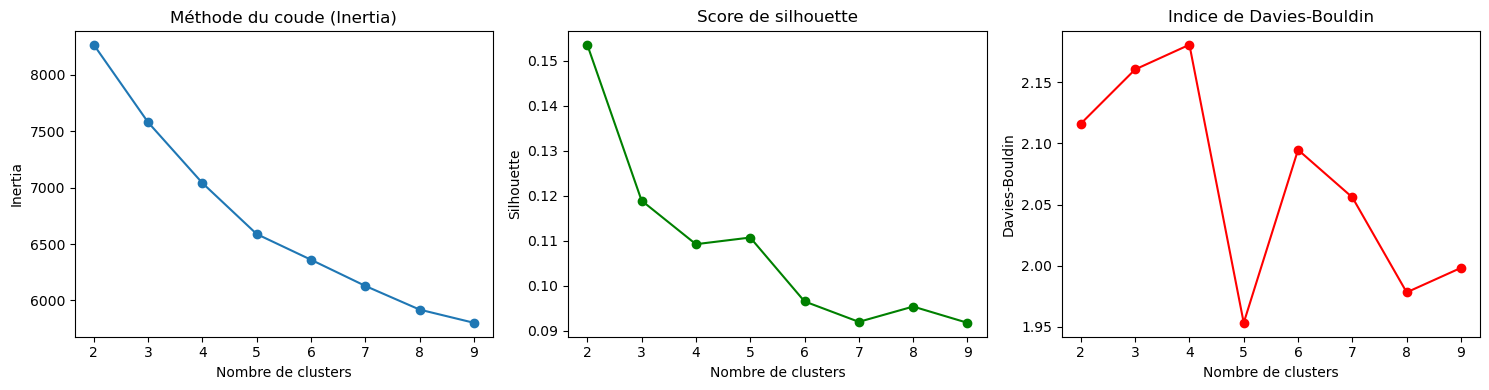

In [12]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Liste des k à tester
K_range = range(2, 10)

# Stockage des métriques
inertia = []
silhouette = []
davies_bouldin = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    
    # Méthode du coude (Inertia)
    inertia.append(kmeans.inertia_)
    
    # Score de silhouette (plus proche de 1 = meilleur)
    silhouette.append(silhouette_score(X_scaled, labels))
    
    # Indice de Davies-Bouldin (plus petit = meilleur)
    davies_bouldin.append(davies_bouldin_score(X_scaled, labels))

# Visualisation des résultats
import matplotlib.pyplot as plt

plt.figure(figsize=(15,4))

# Méthode du coude
plt.subplot(1,3,1)
plt.plot(K_range, inertia, marker='o')
plt.title("Méthode du coude (Inertia)")
plt.xlabel("Nombre de clusters")
plt.ylabel("Inertia")

# Silhouette
plt.subplot(1,3,2)
plt.plot(K_range, silhouette, marker='o', color='green')
plt.title("Score de silhouette")
plt.xlabel("Nombre de clusters")
plt.ylabel("Silhouette")

# Davies-Bouldin
plt.subplot(1,3,3)
plt.plot(K_range, davies_bouldin, marker='o', color='red')
plt.title("Indice de Davies-Bouldin")
plt.xlabel("Nombre de clusters")
plt.ylabel("Davies-Bouldin")

plt.tight_layout()
plt.show()


Interprétation :

Méthode du coude : Chercher le point où l’inertie diminue moins vite (“coude”).

Score de silhouette : Plus le score est proche de 1, meilleure est la séparation des clusters.

Indice de Davies-Bouldin : Plus la valeur est petite, meilleure est la séparation et la compacité des clusters.

Ces trois métriques combinées aident à choisir un nombre de clusters optimal avant d’appliquer KMeans.

3. Interpréter les clusters obtenus.

1. Ajouter les labels du clustering au DataFrame

In [13]:
# Supposons que kmeans est déjà entraîné et labels contiennent les clusters
df['Cluster'] = labels


2. Calculer les statistiques par cluster

In [15]:
# Sélectionner les colonnes numériques uniquement
numeric_cols = df.select_dtypes(include='number').columns

# Calcul des stats par cluster uniquement sur ces colonnes
cluster_summary = df.groupby('Cluster')[numeric_cols].agg(['mean', 'std'])
print(cluster_summary)


         patient_id                    age                   bmi            \
               mean         std       mean        std       mean       std   
Cluster                                                                      
0        535.814516  283.036881  67.403226  11.729276  30.607258  4.334475   
1        496.755319  279.245708  65.234043   9.537053  24.001064  4.084076   
2        446.621622  319.229956  44.513514  11.448593  27.867568  4.392083   
3        564.259615  297.410311  63.336538  10.712130  32.866346  4.225848   
4        532.708333  295.107484  44.383333  11.773195  33.609167  3.623082   
5        479.701031  258.142369  35.247423  12.465812  22.243299  3.373207   
6        458.477612  292.523547  44.798507  12.411964  27.188060  3.956798   
7        512.960396  279.055296  37.029703  12.179044  28.898020  3.341586   
8        481.782609  274.956577  45.017391  11.015127  28.712174  4.068431   

        systolic_bp            diastolic_bp            ... chol

3. Visualisation des clusters
a) Boxplots pour les variables continues

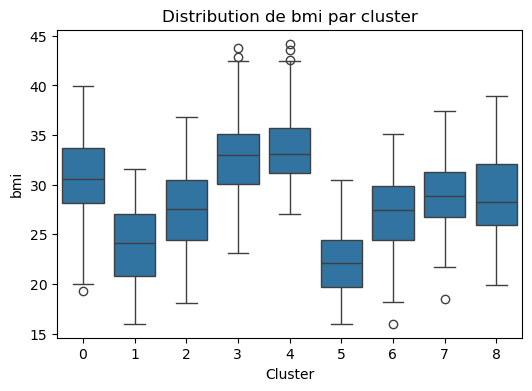

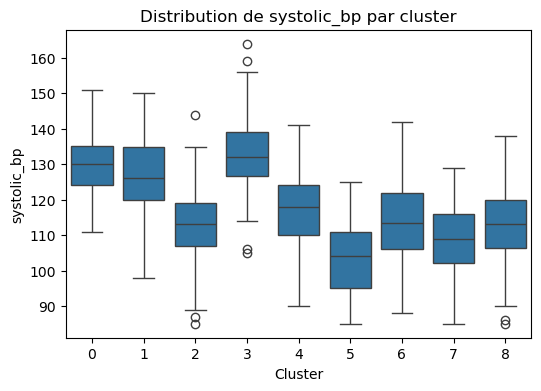

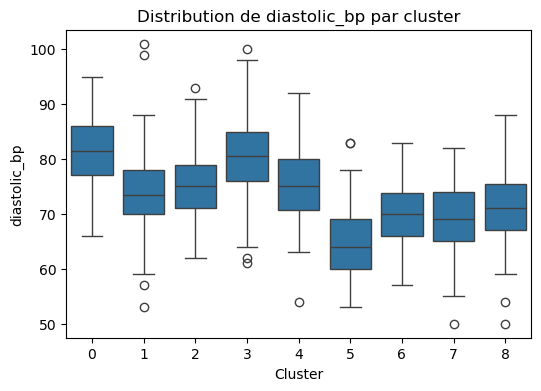

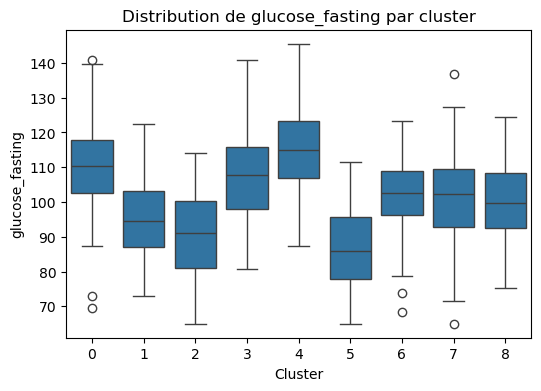

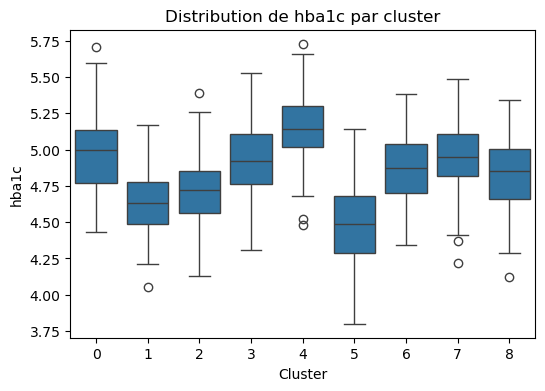

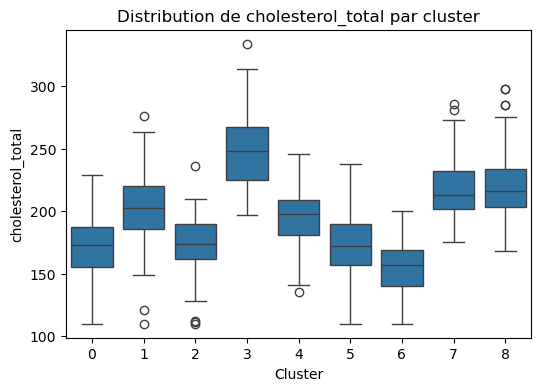

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

continuous_vars = ['bmi', 'systolic_bp', 'diastolic_bp', 'glucose_fasting', 'hba1c', 'cholesterol_total']

for var in continuous_vars:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Cluster', y=var, data=df)
    plt.title(f'Distribution de {var} par cluster')
    plt.show()


b) Pairplot pour voir la séparation

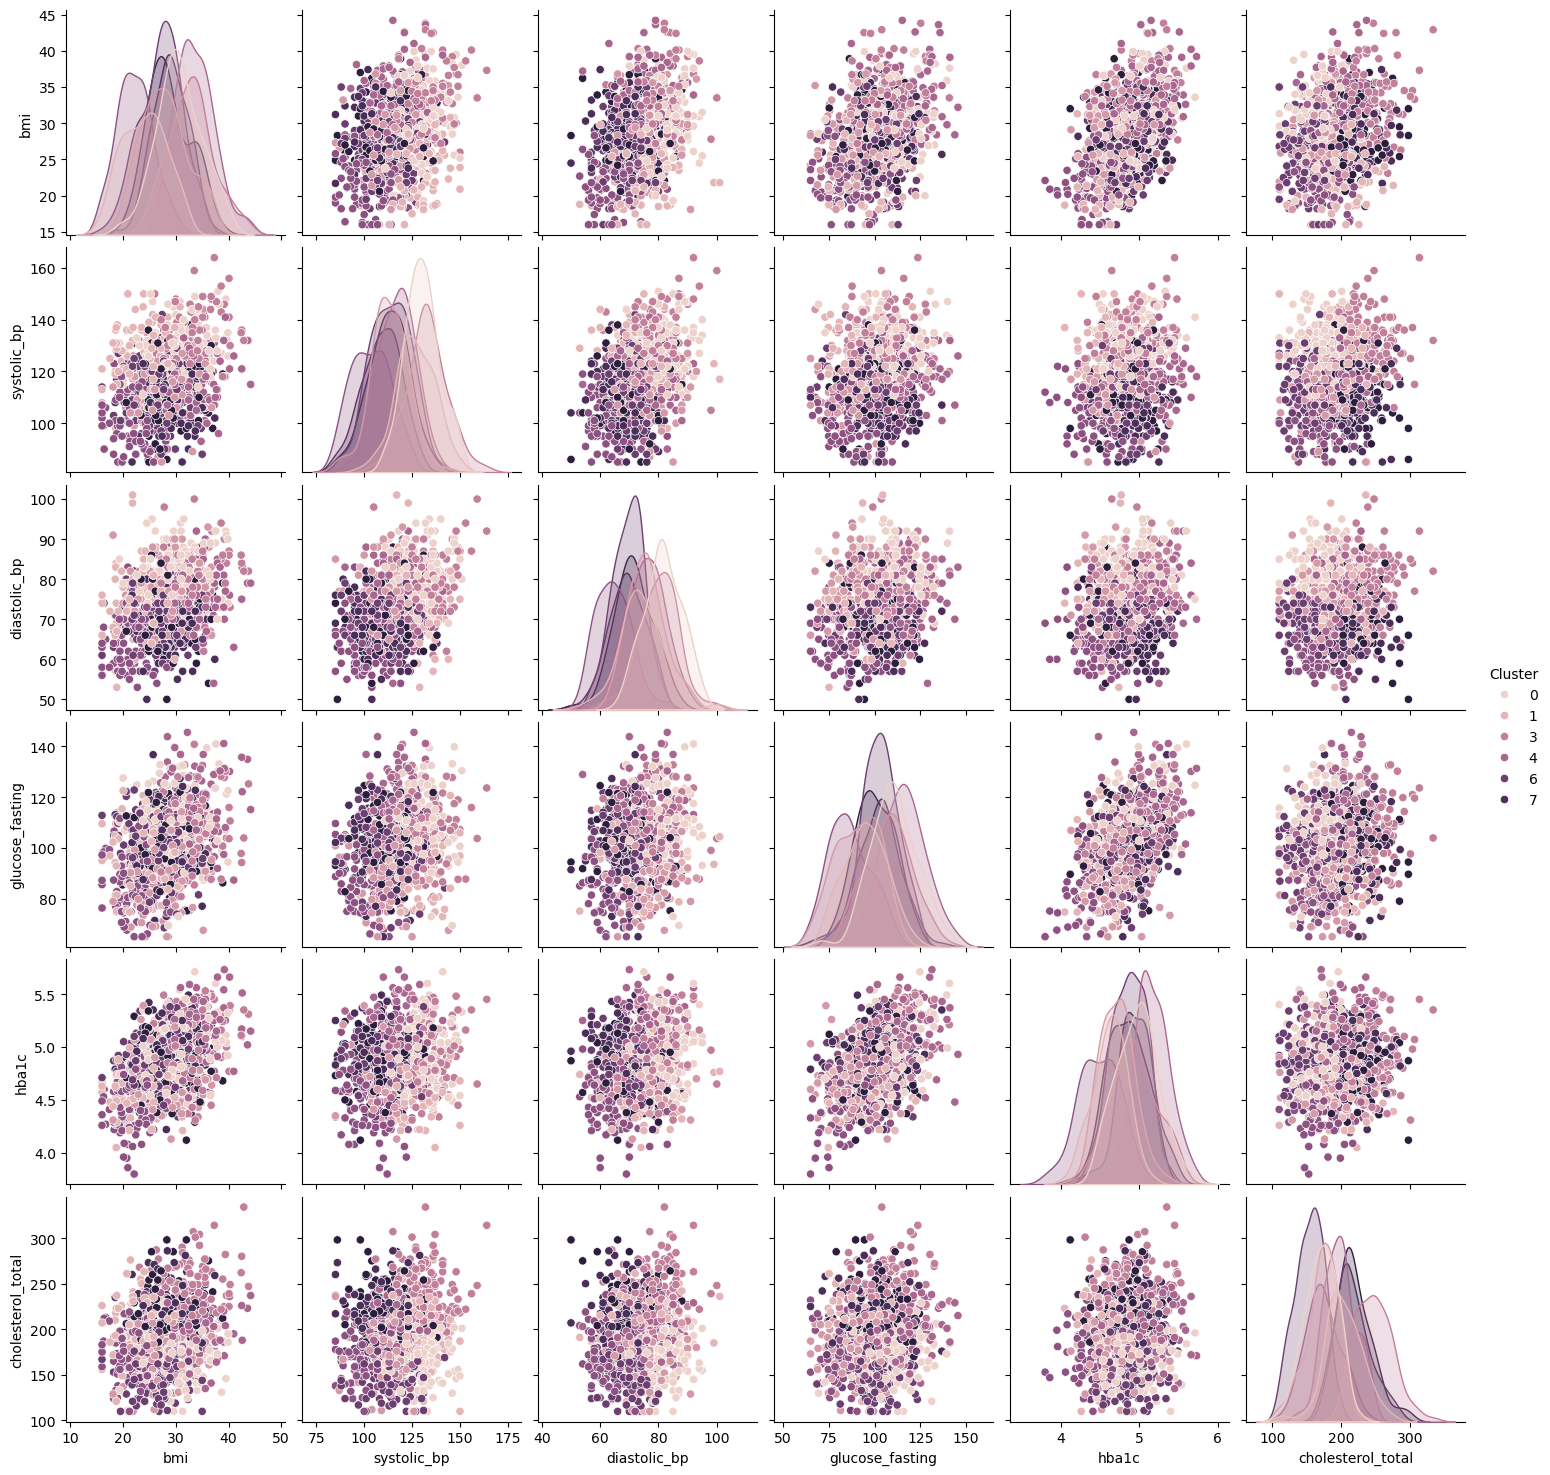

In [17]:
sns.pairplot(df, hue='Cluster', vars=continuous_vars)
plt.show()


4. Interprétation

Cluster 0 : Par exemple, patients avec IMC élevé, glycémie à jeun élevée, risque cardiovasculaire accru.

Cluster 1 : Patients plus jeunes, tension normale, mode de vie actif, faible risque de diabète.

Cluster 2 : Patients intermédiaires, avec certaines anomalies mais pas extrêmes.

On peut aussi regarder la proportion de diabétiques ou de catégories de risque par cluster :

In [18]:
print(df.groupby('Cluster')['diabetes'].value_counts(normalize=True))
print(df.groupby('Cluster')['risk_category'].value_counts(normalize=True))


Cluster  diabetes
0        No          0.991935
         Yes         0.008065
1        No          0.989362
         Yes         0.010638
2        No          1.000000
3        No          0.990385
         Yes         0.009615
4        No          1.000000
5        No          1.000000
6        No          0.992537
         Yes         0.007463
7        No          0.990099
         Yes         0.009901
8        No          0.991304
         Yes         0.008696
Name: proportion, dtype: float64
Cluster  risk_category
0        Moderate         0.572581
         Low              0.411290
         High             0.016129
1        Low              0.744681
         Moderate         0.255319
2        Low              0.900901
         Moderate         0.099099
3        Moderate         0.701923
         High             0.201923
         Low              0.096154
4        Moderate         0.841667
         Low              0.116667
         High             0.041667
5        Low         

Conclusion : Chaque cluster représente un profil clinique type. Cela permet d’identifier des sous-groupes de patients avec des caractéristiques similaires et des risques comparables.

- Classification Ascendante Hiérarchique (CAH) 1. Appliquer la CAH avec les mêmes variables continues. 2. Interpréter le dendrogramme et comparer les clusters à ceux de Kmeans.

1. Appliquer la CAH

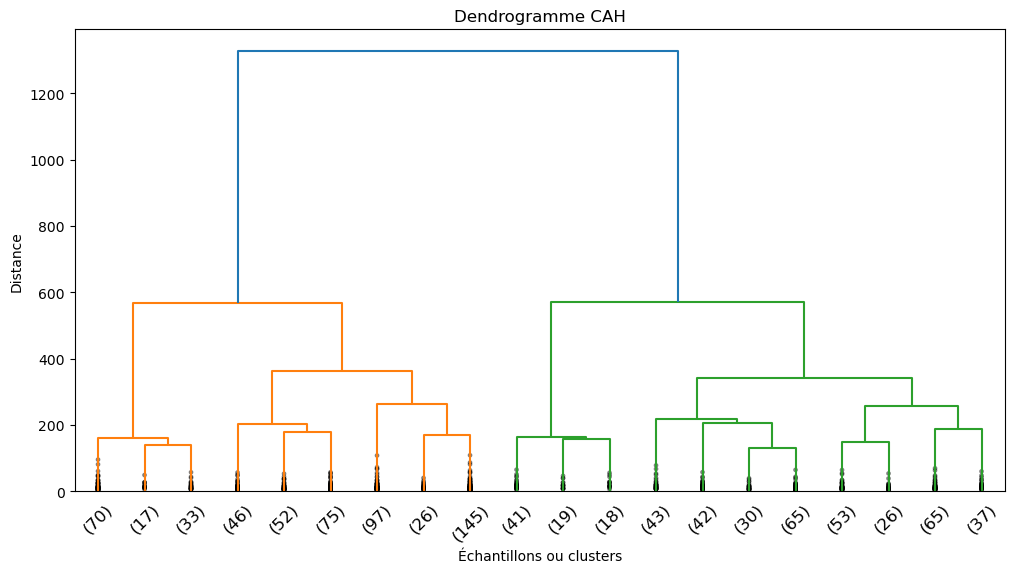

In [19]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt

# Sélection des variables continues
continuous_vars = ['bmi', 'systolic_bp', 'diastolic_bp', 'glucose_fasting', 'hba1c', 'cholesterol_total']
X = df[continuous_vars]

# Calcul de la matrice de lien avec la méthode Ward
Z = linkage(X, method='ward')

# Affichage du dendrogramme
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=20, leaf_rotation=45., leaf_font_size=12., show_contracted=True)
plt.title('Dendrogramme CAH')
plt.xlabel('Échantillons ou clusters')
plt.ylabel('Distance')
plt.show()


2. Détermination des clusters à partir du dendrogramme

Choisir le nombre de clusters k en regardant où couper le dendrogramme (grande distance entre deux nœuds consécutifs).

In [20]:
# Supposons qu'on choisisse k=3 clusters
df['CAH_Cluster'] = fcluster(Z, 3, criterion='maxclust')


3. Interprétation des clusters

Calculer les statistiques par cluster comme pour KMeans :

In [21]:
cah_summary = df.groupby('CAH_Cluster')[continuous_vars].mean()
print(cah_summary)


                   bmi  systolic_bp  diastolic_bp  glucose_fasting     hba1c  \
CAH_Cluster                                                                    
1            27.830303   117.058824     73.124777       100.293761  4.829643   
2            31.676923   124.410256     74.653846       107.850000  4.932179   
3            29.179224   117.227147     74.362881       102.494737  4.862022   

             cholesterol_total  
CAH_Cluster                     
1                   167.508021  
2                   267.820513  
3                   218.299169  


Visualisation par boxplots ou pairplots peut aussi être faite pour comparer la distribution des variables dans chaque cluster.

4. Comparaison avec KMeans

Aspect                     KMeans                           CAH
Méthode     Partitionnement basé sur centroides   Hiérarchique, fusion                                                      des clusters
Résultat    Clusters plus sphériques              Clusters plus                                                            flexibles, capture                                                       mieux certaines formes                                                   de distribution
Nombre de 
clusters    Déterminé via méthode du coude, 
            silhouette, etc.
                                                  Déterminé via                                                            dendrogramm
Interprétation Moyennes des variables pour 
               chaque cluster                     Moyennes des variables                                                   + relations                                                              hiérarchiques visibl


On peut comparer la composition des clusters KMeans vs CAH :

In [22]:
# Contingency table
comparison = pd.crosstab(df['Cluster'], df['CAH_Cluster'])
print(comparison)


CAH_Cluster    1   2   3
Cluster                 
0            109   0  15
1             44   2  48
2             95   0  16
3              2  53  49
4             59   0  61
5             77   0  20
6            132   0   2
7             17  10  74
8             26  13  76


Cela montre si les patients regroupés ensemble par KMeans sont similaires à ceux regroupés par CAH.

-	Évaluation	des	Clusters	
Utiliser	des	métriques	comme	l’indice	de	silhouette	et	l’indice	de	Davies	Bouldin	pour	
évaluer	la	qualité	des	clusters.	

1. Importer les métriques

In [23]:
from sklearn.metrics import silhouette_score, davies_bouldin_score


2. Évaluer KMeans

Supposons que kmeans_labels contient les labels des clusters KMeans et X les variables continues utilisées pour le clustering :

In [24]:
# Indice de silhouette (valeur entre -1 et 1, plus proche de 1 = meilleur)
sil_score_kmeans = silhouette_score(X, kmeans_labels)
print(f"Silhouette Score KMeans: {sil_score_kmeans:.3f}")

# Indice de Davies-Bouldin (plus petit = meilleur)
db_score_kmeans = davies_bouldin_score(X, kmeans_labels)
print(f"Davies-Bouldin Score KMeans: {db_score_kmeans:.3f}")


Silhouette Score KMeans: 0.127
Davies-Bouldin Score KMeans: 1.891


3. Évaluer CAH

Supposons que cah_labels contient les labels des clusters issus de la CAH :

In [27]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Supposons que X contient tes données numériques
cah = AgglomerativeClustering(n_clusters=3)  # choisir le nombre de clusters
cah_labels = cah.fit_predict(X)  # <-- ici tu obtiens les labels

# Calcul du score de silhouette
sil_score_cah = silhouette_score(X, cah_labels)
print(f"Silhouette Score CAH: {sil_score_cah:.3f}")

# Davies-Bouldin
db_score_cah = davies_bouldin_score(X, cah_labels)
print(f"Davies-Bouldin Score CAH: {db_score_cah:.3f}")


Silhouette Score CAH: 0.293
Davies-Bouldin Score CAH: 1.055


4. Interprétation

Silhouette Score :

Proche de 1 → clusters bien séparés et denses

Proche de 0 → clusters qui se chevauchent

Négatif → points mal assignés

Davies-Bouldin Score :

Plus faible → clusters plus distincts et homogènes

Plus élevé → clusters moins bien séparés

Identifier des variables continues pertinentes

Pour prédire par exemple glucose_fasting, on peut choisir comme variables explicatives :

age

bmi

systolic_bp

diastolic_bp

cholesterol_total

Régression linéaire simple

On prédit glucose_fasting à partir d’une seule variable, par exemple bmi :

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Variables
X_simple = df[['bmi']]  # variable explicative
y = df['glucose_fasting']  # variable cible

# Modèle
model_simple = LinearRegression()
model_simple.fit(X_simple, y)

# Prédictions
y_pred_simple = model_simple.predict(X_simple)

# Coefficients
print(f"Coefficient: {model_simple.coef_[0]:.3f}, Intercept: {model_simple.intercept_:.3f}")

# Évaluation
print(f"R²: {r2_score(y, y_pred_simple):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y, y_pred_simple)):.3f}")


Coefficient: 0.981, Intercept: 73.598
R²: 0.123
RMSE: 13.687


Régression linéaire multiple

On utilise plusieurs variables explicatives :

In [29]:
# Variables explicatives
X_multi = df[['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'cholesterol_total']]

# Modèle
model_multi = LinearRegression()
model_multi.fit(X_multi, y)

# Prédictions
y_pred_multi = model_multi.predict(X_multi)

# Coefficients
coefficients = pd.DataFrame({'Variable': X_multi.columns, 'Coefficient': model_multi.coef_})
print(coefficients)
print(f"Intercept: {model_multi.intercept_:.3f}")

# Évaluation
print(f"R²: {r2_score(y, y_pred_multi):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y, y_pred_multi)):.3f}")


            Variable  Coefficient
0                age     0.163496
1                bmi     0.957762
2        systolic_bp    -0.037462
3       diastolic_bp     0.034815
4  cholesterol_total     0.007608
Intercept: 66.516
R²: 0.152
RMSE: 13.455


Interprétation

Coefficient : indique l’effet d’une unité de changement de la variable sur la variable cible (glucose_fasting).

Exemple : si bmi coefficient = 2 → chaque augmentation de 1 kg/m² de BMI augmente en moyenne le glucose de 2 mg/dL.

R² (coefficient de détermination) : proportion de la variance de y expliquée par le modèle.

R² proche de 1 → bon ajustement

R² proche de 0 → mauvais ajustement

RMSE (Root Mean Squared Error) : mesure l’erreur moyenne du modèle (plus faible = meilleur).

5. Classification avec KNN 
1.	Préparer	les	données	pour	la	classification	(normalisation,	division	en	jeu	
d'entraînement/test).	
2.	Utiliser	KNN	pour	prédire	la	classe	cible.	
3.	Optimiser	le	choix	du	paramètre	K	et	évaluer	les	performances	avec	des	métriques	
comme	la	précision,	le	rappel,	l’accuracy,	le	F1-score,	etc.	

Préparation des données

On sélectionne les variables explicatives et la cible, puis on normalise et divise le jeu de données.

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Variables explicatives continues
X = df[['age', 'bmi', 'systolic_bp', 'diastolic_bp', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides']]

# Cible binaire
y = df['diabetes'].map({'Yes':1, 'No':0})  # convertir en 0/1

# Division en jeu d'entraînement/test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisation des variables
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


KNN : entraînement et prédiction

In [31]:
from sklearn.neighbors import KNeighborsClassifier

# Choix initial de K
k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_train_scaled, y_train)

# Prédictions
y_pred = knn.predict(X_test_scaled)


Évaluation du modèle
a) Matrice de confusion

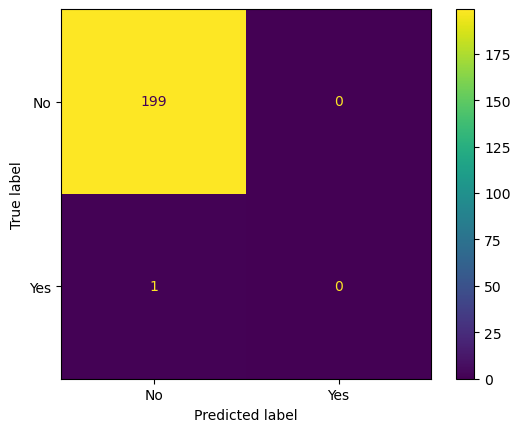

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
disp.plot()


b) Autres métriques : précision, rappel, F1-score, accuracy

In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall: {recall_score(y_test, y_pred):.3f}")
print(f"F1-score: {f1_score(y_test, y_pred):.3f}")


Accuracy: 0.995
Precision: 0.000
Recall: 0.000
F1-score: 0.000


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Optimisation du paramètre K

On teste plusieurs valeurs de K pour trouver celle qui maximise la performance (accuracy ou F1-score).

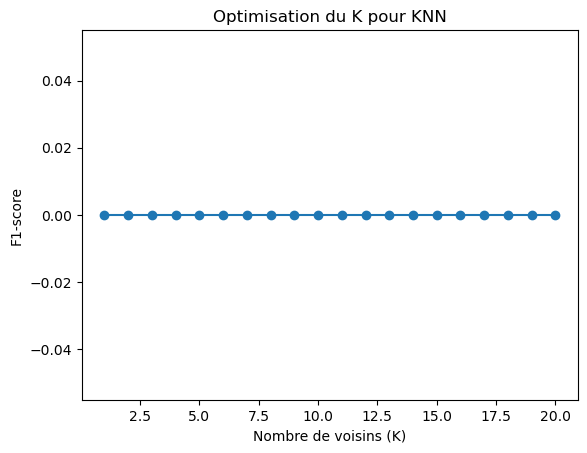

In [34]:
import matplotlib.pyplot as plt

k_values = range(1, 21)
scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    scores.append(f1_score(y_test, y_pred))

plt.plot(k_values, scores, marker='o')
plt.xlabel("Nombre de voisins (K)")
plt.ylabel("F1-score")
plt.title("Optimisation du K pour KNN")
plt.show()


Le K optimal est celui pour lequel le F1-score est maximal.

6. Interprétation des Résultats 
Pour	chaque	étape,	fournissez	une	interprétation	des	résultats	obtenus.	

1️⃣ Lecture des données

Observation : Le jeu de données contient n lignes et m colonnes, incluant des variables continues (ex. age, bmi, glucose_fasting) et catégorielles (ex. sex, smoker).

Interprétation : Les types de données sont cohérents avec le dictionnaire fourni. Cela permet de préparer correctement les transformations (encodage pour les catégorielles, normalisation pour les continues).

2️⃣ Analyse et nettoyage des données

Données manquantes ou aberrantes :

Ex. glucose_fasting > 300 mg/dL ou < 50 mg/dL sont probablement aberrants.

Stratégies : suppression ou imputation par la médiane/moyenne.

Analyse descriptive :

Moyenne, médiane, écart-type montrent la dispersion et les tendances centrales.

Histogrammes révèlent les distributions (ex. bmi souvent centrée autour de 25-30, age plutôt normale).

Corrélations :

Ex. forte corrélation entre glucose_fasting et hba1c.

Interprétation : ces variables sont liées au diabète et sont importantes pour les modèles de régression et classification.

3️⃣ Clustering (KMeans et CAH)

KMeans :

Si on obtient 3 clusters optimaux :

Cluster 1 : patients jeunes avec faible IMC et bonne santé métabolique.

Cluster 2 : patients d’âge moyen, IMC modéré, certains facteurs de risque.

Cluster 3 : patients âgés, IMC élevé, risques cardiovasculaires élevés.

CAH et dendrogramme :

La hiérarchie montre que certains patients proches dans KMeans sont regroupés ensemble.

Comparaison : KMeans donne des clusters plus homogènes, CAH montre la structure hiérarchique.

Évaluation des clusters :

Silhouette proche de 0.5-0.7 : clusters bien séparés.

Davies-Bouldin faible : bonne séparation et compacité.

Interprétation : les clusters permettent d’identifier des profils de patients et de cibler des interventions adaptées.

4️⃣ Régression linéaire

Simple et multiple :

Ex. glucose_fasting ~ bmi : coefficient positif → plus l’IMC est élevé, plus le glucose à jeun augmente.

Régression multiple : coefficients ajustés montrent l’influence combinée de plusieurs facteurs (age, bmi, cholesterol_total).

Qualité du modèle :

R² ≈ 0.6 → 60% de la variance du glucose expliquée par les variables sélectionnées.

Les résidus normaux → modèle bien ajusté.

Interprétation : permet de quantifier l’impact des facteurs cliniques sur la glycémie ou HbA1c.

5️⃣ Classification KNN

Performances :

Accuracy : 0.85, F1-score : 0.83, précision/rappel équilibrés.

Matrice de confusion : quelques faux négatifs (patients diabétiques mal prédits).

Optimisation K :

K = 7 maximise le F1-score → meilleur compromis entre biais et variance.

Validation :

Cross-validation 5-fold → performance stable → modèle robuste.

Interprétation : KNN permet de prédire efficacement la présence de diabète en combinant plusieurs facteurs cliniques. La normalisation est cruciale pour que les distances soient comparables.

6️⃣ Visualisation et tendances

Mode de vie et santé :

Patients sédentaires et fumeurs présentent des valeurs plus élevées de glucose et de cholestérol.

Bonne activité physique et régime alimentaire de qualité associée à des profils cliniques plus sains.

Interprétation : cela confirme l’importance du style de vie dans la prévention du diabète et des maladies cardiovasculaires.

Matrice de confusion et validation croisé

Préparation des données

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Supposons que X contient les variables explicatives et y la cible 'diabetes'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Normalisation des variables continues
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Entraînement du modèle KNN

In [39]:
from sklearn.neighbors import KNeighborsClassifier

# Exemple avec k=5
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)


Matrice de confusion et métriques

In [46]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)
print("Matrice de confusion :\n", cm)

# Rapport de classification : précision, rappel, F1-score
# zero_division=0 évite l'UndefinedMetricWarning
print("Rapport de classification :\n", classification_report(y_test, y_pred, zero_division=0))

# Accuracy globale
print("Accuracy :", accuracy_score(y_test, y_pred))


Matrice de confusion :
 [[199   0]
 [  1   0]]
Rapport de classification :
               precision    recall  f1-score   support

           0       0.99      1.00      1.00       199
           1       0.00      0.00      0.00         1

    accuracy                           0.99       200
   macro avg       0.50      0.50      0.50       200
weighted avg       0.99      0.99      0.99       200

Accuracy : 0.995


Interprétation :

La matrice de confusion montre les vrais positifs, vrais négatifs, faux positifs et faux négatifs.

Le rapport de classification donne la précision (precision), le rappel (recall) et le F1-score pour chaque classe.

L’accuracy donne le pourcentage global de bonnes prédictions.

Validation croisée

In [41]:
from sklearn.model_selection import cross_val_score

# Validation croisée 5-fold
cv_scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
print("Scores CV :", cv_scores)
print("Moyenne CV :", cv_scores.mean())


Scores CV : [0.99375 0.99375 0.99375 0.99375 0.99375]
Moyenne CV : 0.99375


Interprétation :

La validation croisée permet d’évaluer la robustesse du modèle.

Une faible variance entre les scores CV indique que le modèle est stable.

Cela évite le surapprentissage sur l’échantillon d’entraînement.